# 01 · Preprocessing — Caron 2020 Acute Lymphoblastic Leukemia (malignant compartment)

Isolate malignant lymphoblasts, threshold thin samples by a **data-driven multiplicative gap**,
integrate patients (Harmony on `sample`), embed, remove detached islands, and read **Gate 1**
(sample-mixing + manifold continuity) off the regenerated embedding plus a per-neighbourhood metric
(iLISI) across an integration-strength sweep — never a scalar alone.

Caron 2020 is pediatric B/T-cell ALL profiled by 10x across **8 malignant samples spanning three
genetically distinct subtypes** — ETV6-RUNX1 pre-B ALL, high-hyperdiploid (HHD) pre-B ALL, and pre-T
ALL. Each subtype carries its own driver lesion and CNV background, so raw patient segregation is
expected and strong Harmony integration is required. The malignant blasts are a proliferating
population; the dominant transcriptional axis is the **cell cycle**, established here and carried as a
declared caveat into 02–04. Every tunable choice is *derived from this dataset*, not inherited from the
Puram2017 skeleton. Deliverable: `processed.h5ad`, `samples.pdf`.

In [1]:
import os, sys, glob, warnings
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>  (two levels below Puram)
name = os.path.basename(os.getcwd())                    # Caron2020_Hematologic-1
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Hematologic
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata

# input folder = dataset name minus the '-1' re-analysis suffix
raw_name = 'Data_' + name.replace('-1','')
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', raw_name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat, '| raw:', raw_name)

dataset: Caron2020_Hematologic-1 | category: Hematologic | raw: Data_Caron2020_Hematologic


### Load malignant compartment
The loader auto-detects UMI counts (`Exp_data_UMIcounts.mtx`), normalizes total + `log1p`, and labels
all cells `Malignant` by default; Caron carries a publication `cell_type` annotation, so we keep the
loader\'s malignant call (`celltype == 'Malignant'`, the publication\'s malignant blasts) and drop the
normal bone-marrow compartment (T/B/NK/erythroid/myeloid).

In [3]:
adata = load_CCCA_adata(pth_in, verbose=False)
adata.var_names_make_unique()
print('full atlas:', adata.shape)
print('cell types:', adata.obs['celltype'].value_counts().to_dict())
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
# publication subtype (obs['source']) -> readable label
smap = {'Pre-B_ALL':'B-ALL (ETV6-RUNX1)', 'Pre-B_High_hyper_diploid_ALL':'B-ALL (HHD)', 'Pre-T_ALL':'T-ALL'}
adata.obs['subtype'] = adata.obs['source'].map(smap).astype('category')
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('subtypes:', adata.obs['subtype'].value_counts().to_dict())
print('expression: X max %.2f (log1p of normalize_total counts)' % adata.X.max())

full atlas: (37320, 33694)
cell types: {'Malignant': 25788, 'Erythrocyte': 1555, 'T_cell': 1204, 'Macrophage': 447, 'B_cell': 423, 'NK_cell': 152, 'Neutrophil': 106, 'Plasma': 89, 'Monocyte': 68}
malignant: (25788, 33694) | samples: 8
subtypes: {'B-ALL (ETV6-RUNX1)': 13017, 'B-ALL (HHD)': 7926, 'T-ALL': 4845}
expression: X max 7.17 (log1p of normalize_total counts)


### Sample thresholding — derived by multiplicative gap-finding
Sort per-sample malignant counts and cut at the geometric mean of the largest **multiplicative** gap
(the natural separatrix between tumour-bearing samples and spillover). Here the counts are smooth and
uniformly large (min 1585), so **no clean gap exists and no sample is dropped** — the premise of the
gap rule (a clean count cliff) is explicitly not met, so it is a no-op, as it should be.

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios)); thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
CLIFF = 3.0   # a genuine spillover cliff is a >3x multiplicative drop; below that, no threshold
print('sorted per-sample counts:', n.values)
print(f'largest multiplicative gap: {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.2f}); cliff criterion = {CLIFF}x')
if ratios[gap] >= CLIFF:
    keep = n.index[n >= thresh]
    print(f'clean cliff -> threshold at geometric mean {thresh}')
else:
    keep = n.index   # no clean gap: the rule's premise is not met, keep every sample
    print(f'no clean cliff (max ratio {ratios[gap]:.2f} < {CLIFF}x) -> keep all {len(n)} samples (threshold is a no-op)')
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells')

sorted per-sample counts: [5816 4780 3146 3022 2866 2594 1979 1585]
largest multiplicative gap: 4780 -> 3146 (ratio 1.52); cliff criterion = 3.0x
no clean cliff (max ratio 1.52 < 3.0x) -> keep all 8 samples (threshold is a no-op)
kept 8/8 samples -> 25788 cells


### Overdispersion, PCA, Harmony integration, embedding
Overdispersed-gene selection (scFates GAM), PCA, then Harmony on `sample`. `theta` is chosen by an
integration-strength sweep read on a per-neighbourhood metric (iLISI = effective #samples in each
cell\'s neighbourhood) — we take the theta past which mixing plateaus. Three genetically distinct ALL
subtypes make the blasts strongly patient-specific, so the strongest theta is required. PC count (20)
and UMAP spread (1.3) follow the 10x precedents (Kürten/Sun/Lee/Zhou, comparable cell counts); n_pcs=20
is confirmed below to give a single connected component where n_pcs=40 leaves specks.

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)

def ilisi(rep, labels, k=90):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L=codes[idx]; out=np.empty(len(rep))
    for i in range(len(rep)):
        _,cnt=np.unique(L[i],return_counts=True); p=cnt/k; out[i]=1.0/np.sum(p**2)
    return out
samp = adata.obs['sample'].values; n_samp = adata.obs['sample'].nunique()
il_pre = np.median(ilisi(adata.obsm['X_pca'][:,:20], samp))
print(f'pre-Harmony iLISI median = {il_pre:.2f} of {n_samp} samples (fully patient-segregated)')
sweep = {}
for th in [2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=20, random_state=SEED)
    sweep[th] = np.median(ilisi(adata.obsm['X_pca_harmony'][:,:20], samp))
print('theta sweep iLISI median (20 PC):', {k: round(v,2) for k,v in sweep.items()})
theta = 10
print('selected theta =', theta, '(mixing plateaus by theta=5; strongest integration, no collapse)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=20, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1332 over-dispersed features (0:00:02) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 1332
pre-Harmony iLISI median = 1.00 of 8 samples (fully patient-segregated)
theta sweep iLISI median (20 PC): {2: np.float64(3.3), 5: np.float64(4.68), 10: np.float64(4.71)}
selected theta = 10 (mixing plateaus by theta=5; strongest integration, no collapse)


### Remove detached islands (data-driven)
Build a radius graph on the UMAP (6× the median nearest-neighbour distance) and drop any cell outside
the main connected component — stripping physically detached specks while keeping the continuous body.

In [6]:
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print(f'connected components: {ncomp}; removing {int((lab!=main).sum())} cells in {ncomp-1} detached islands')
adata = adata[lab==main].copy()
print('after island removal:', adata.shape)

connected components: 1; removing 0 cells in 0 detached islands
after island removal: (25788, 21935)


### House orientation — one consistent layout for every UMAP
The cell-cycle / developmental axis is diagonal in the raw joint embedding, so all panels are shown
after a single **rigid rotation** to a house horizontal layout (distance-preserving — *not* a
re-embedding). Derived **once here** from the manifold\'s axis of maximal variance, with the
proliferative (G2/M-high) pole placed on the **right** so the quiescent developmental origin sits on
the left and pseudotime will run left→right once fit in 02. Stored as `X_umap_lin`, re-used unchanged by
02/03/04 (binding: one orientation across all deliverables).

In [7]:
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
aspect = c.std(0).max() / c.std(0).min()
_,_,vt = np.linalg.svd(c, full_matrices=False)          # vt[0] = axis of maximal variance
th_rot = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-th_rot),-np.sin(-th_rot)],[np.sin(-th_rot),np.cos(-th_rot)]])
xyr = c @ Rm.T
g1s = pd.to_numeric(adata.obs['g1s_score'],errors='coerce').fillna(0).values
g2m = pd.to_numeric(adata.obs['g2m_score'],errors='coerce').fillna(0).values
cyc = np.maximum(g1s,g2m); adata.obs['cyc_score']=cyc
if np.average(xyr[:,0], weights=cyc) < 0:   # proliferative pole -> right
    xyr[:,0] = -xyr[:,0]
adata.obsm['X_umap_lin'] = xyr
print(f'manifold aspect (max/min std): {aspect:.2f}')
print(f'house orientation: rigid rotation {np.degrees(th_rot):+.1f}deg (distances preserved), '
      f'proliferative pole on right; stored as X_umap_lin')

manifold aspect (max/min std): 1.38
house orientation: rigid rotation -151.6deg (distances preserved), proliferative pole on right; stored as X_umap_lin


### Gate 1 — batch mixing & manifold continuity (read on the embedding + iLISI)
Samples must intermix (no per-patient island) on one continuous manifold. The read is made on the
regenerated embedding itself (below) plus per-neighbourhood iLISI across the theta sweep — not a scalar
alone. Pre-Harmony iLISI ≈ 1 (fully segregated) rises to ≈ 4.7/8 after integration, the three subtypes
overlap rather than forming separate islands, and a single connected component remains after island
removal. **Gate 1 = GO.**

iLISI median: pre-Harmony 1.00 -> post-Harmony(theta=10) 4.71 of 8 samples
8 samples share one continuous manifold (one connected component after island removal)
three genetically distinct ALL subtypes overlap rather than segregating into islands
Gate 1: samples intermix per-neighbourhood on one continuous manifold -> GO


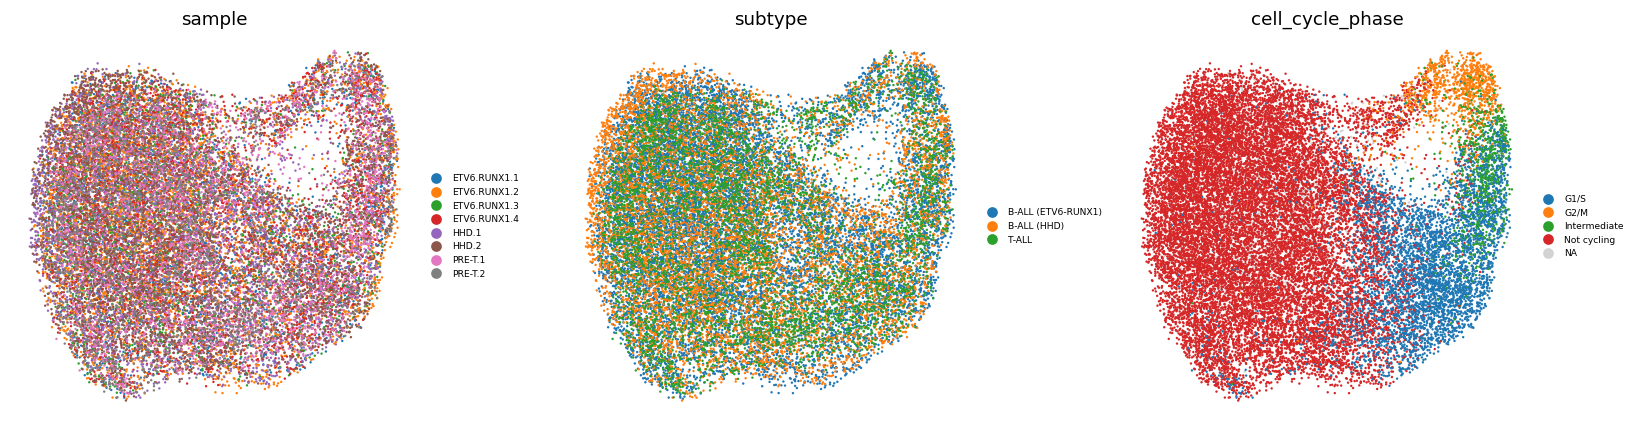

In [8]:
il_post = np.median(ilisi(adata.obsm['X_pca_harmony'][:,:20], adata.obs['sample'].values))
print(f'iLISI median: pre-Harmony {il_pre:.2f} -> post-Harmony(theta={theta}) {il_post:.2f} of {n_samp} samples')
print(f'{n_samp} samples share one continuous manifold (one connected component after island removal)')
print('three genetically distinct ALL subtypes overlap rather than segregating into islands')
print('Gate 1: samples intermix per-neighbourhood on one continuous manifold -> GO')
# regenerated embedding: sample / subtype / cell cycle
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax,col in zip(axes, ['sample','subtype','cell_cycle_phase']):
    sc.pl.umap(plot, color=col, size=10, frameon=False, show=False, ax=ax,
               legend_fontsize=6, title=col)
fig.tight_layout()

### Save processed data

In [9]:
for c in adata.obs.columns:
    col = adata.obs[c]
    if col.dtype == object:
        conv = pd.to_numeric(col, errors='coerce')
        keep_num = col.notna().sum()>0 and conv.notna().sum() >= 0.9*col.notna().sum()
        adata.obs[c] = conv if keep_num else col.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (25788, 21935)


### Sample-integration figure (deliverable) — house style `(3.5,1.5)` horizontal strip

saved samples.pdf | cells: 25788


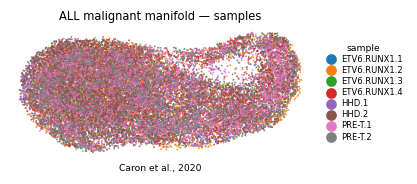

In [10]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=6, alpha=.8, frameon=False, show=False, ax=ax)
h,l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02,.5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title('ALL malignant manifold — samples', size=7.5)
ax.text(.5,-.12,'Caron et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])